# CS 451/651: Data-Intensive Distributed Computing (Fall 2025)
# Assignment 6: Simple Graph Analysis

Read the setup of this assignment in the <a href="https://lintool.github.io/cs451-2025f/assignments/assignment6.html">assignment 6 landing page</a> before you get started here.

First, set up Spark.
This should be routine by now.

In [2]:
%%capture
# No need for output
#self - use env cs451 cause it has the supported python version


import os, sys

# Force Spark to use the same Python as this notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark import SparkConf, SparkContext

conf = SparkConf().setAppName("GraphAnalysis")
# If you want local mode:
conf = conf.setMaster("local[*]")

sc = SparkContext.getOrCreate(conf)
sc.setLogLevel("ERROR")





## 1. Analysis of `ny` Graph

Load data, similar to how it was done in `run_sssp_rdd.py`

In [ ]:
# Paths to your graph data
edges_path = "graph-data/ny/edges.csv"
vertices_path = "graph-data/ny/vertices.csv"

# --- Load edges ---
edges = (
    sc.textFile(edges_path)
    .filter(lambda l: not l.startswith("src"))  # skip header
    .map(lambda l: l.strip().split(","))
    .filter(lambda parts: len(parts) >= 3)      # skip bad lines
    .map(lambda parts: (parts[0], parts[1])) # format as RDD[(src, dst)]
).cache()

num_edges = edges.count()

# --- Load vertices ---
vertices = (
    sc.textFile(vertices_path)
    .filter(lambda l: not l.startswith("id"))  # skip header
    .map(lambda l: l.strip().split(","))
    .filter(lambda parts: len(parts) >= 1)      # skip bad lines
    .map(lambda parts: (parts[0])) # format as RDD[vertix]
).cache()

num_vertices = vertices.count()

print(f"Number of edges = {num_edges}")
print(f"Number of vertices = {num_vertices}")

Number of edges = 733846
Number of vertices = 264346


Given the nature of this graph, the in-degrees and out-degrees are the same!
However, we'll compute both anyways.

Compute mean in-degree (over nodes with non-zero in-degree).
And same for out-degree:

In [4]:
# codecell_1a (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

######### BEGIN STUDENT CODE #########


def compute_out_degree(edges):
    return (
        edges
        .map(lambda x: (x[0], 1))
        .reduceByKey(lambda a, b: a + b)
    )


def compute_in_degree(edges):
    return (
        edges
        .map(lambda x: (x[1], 1))
        .reduceByKey(lambda a, b: a + b)
    )


out_deg = compute_out_degree(edges)
in_deg  = compute_in_degree(edges)

avg_out_nonzero = (
    out_deg.map(lambda x: x[1]).mean()
)

avg_in_nonzero = (
    in_deg.map(lambda x: x[1]).mean()
)


######### END STUDENT CODE #########

print(f"Average out-degree (over nodes with non-zero out-degree): {avg_out_nonzero:.2f}" )
print(f"Average in-degree  (over nodes with non-zero in-degree):  {avg_in_nonzero:.2f}")

Average out-degree (over nodes with non-zero out-degree): 2.78
Average in-degree  (over nodes with non-zero in-degree):  2.78


Compute a histogram of in-degrees and out-degrees:

In [5]:
# codecell_1b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

######### BEGIN STUDENT CODE #########

in_degree_hist = (
    in_deg
    .map(lambda x: (x[1], 1))
    .reduceByKey(lambda a, b: a + b)
)

out_degree_hist = (
    out_deg
    .map(lambda x: (x[1], 1))         
    .reduceByKey(lambda a, b: a + b)
)

in_degree_hist_sorted = in_degree_hist.sortByKey().collect()
out_degree_hist_sorted = out_degree_hist.sortByKey().collect()


######### END STUDENT CODE #########

print("In-degree histogram (degree -> # vertices):")
for deg, cnt in in_degree_hist_sorted:
    print(f"{deg} -> {cnt}")

print("\nOut-degree histogram (degree -> # vertices):")
for deg, cnt in out_degree_hist_sorted:
    print(f"{deg} -> {cnt}")

# The output should be something like:
# 1 -> [count]
# 2 -> [count]
# 3 -> [count]
# ...

In-degree histogram (degree -> # vertices):
1 -> 41050
2 -> 38048
3 -> 126262
4 -> 57341
5 -> 1341
6 -> 285
7 -> 17
8 -> 2

Out-degree histogram (degree -> # vertices):
1 -> 41050
2 -> 38048
3 -> 126262
4 -> 57341
5 -> 1341
6 -> 285
7 -> 17
8 -> 2


Let's plot the degrees.

(If the above is correct, you shouldn't need to do anything other than to run the cell.)

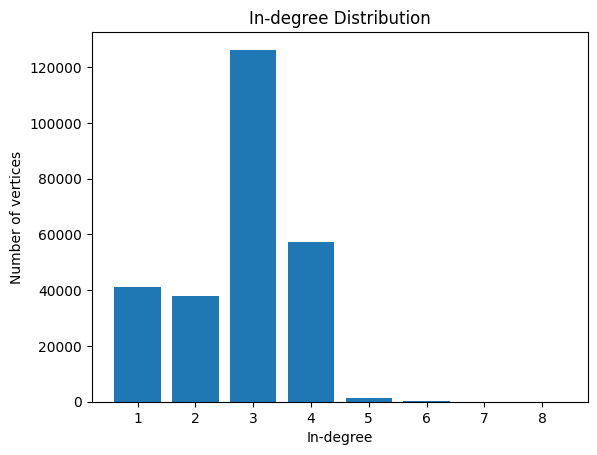

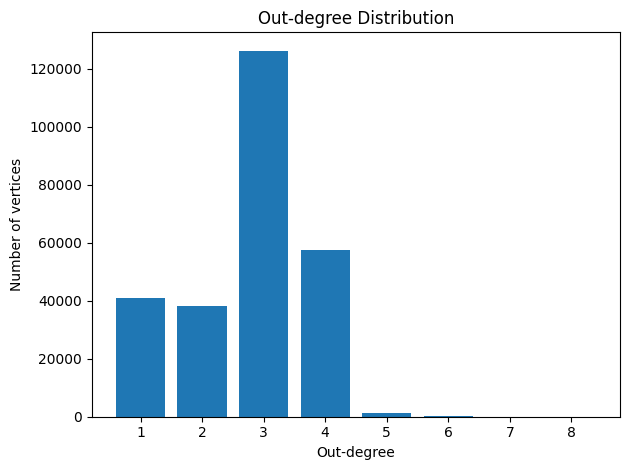

In [6]:
import matplotlib.pyplot as plt

in_degrees_x, in_counts_y = zip(*in_degree_hist_sorted)
out_degrees_x, out_counts_y = zip(*out_degree_hist_sorted)

plt.figure()
plt.bar(in_degrees_x, in_counts_y)
plt.xlabel("In-degree")
plt.ylabel("Number of vertices")
plt.title("In-degree Distribution")

plt.figure()
plt.bar(out_degrees_x, out_counts_y)
plt.xlabel("Out-degree")
plt.ylabel("Number of vertices")
plt.title("Out-degree Distribution")

plt.tight_layout()
plt.show()

Find the maximum in-degree and out-degree (and the vertex that has it):

In [7]:
# codecell_1c (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

######### BEGIN STUDENT CODE #########

max_in_vertex, max_in_deg = in_deg.max(key=lambda x: x[1])

max_out_vertex, max_out_deg = out_deg.max(key=lambda x: x[1])

######### END STUDENT CODE #########

print(f"Max in-degree  = {max_in_deg} (vertex = {max_in_vertex})")
print(f"Max out-degree = {max_out_deg} (vertex = {max_out_vertex})")

Max in-degree  = 8 (vertex = 140961)
Max out-degree = 8 (vertex = 140961)


## 2. Analysis of `ne` Graph

Load data, similar to how it was done in `run_sssp_rdd.py`

In [ ]:
# Paths to your graph data
edges_path = "graph-data/ne/edges.csv"
vertices_path = "graph-data/ne/vertices.csv"

# --- Load edges ---
edges = (
    sc.textFile(edges_path)
    .filter(lambda l: not l.startswith("src"))  # skip header
    .map(lambda l: l.strip().split(","))
    .filter(lambda parts: len(parts) >= 3)      # skip bad lines
    .map(lambda parts: (parts[0], parts[1])) # format as RDD[(src, dst)]
).cache()

num_edges = edges.count()

# --- Load vertices ---
vertices = (
    sc.textFile(vertices_path)
    .filter(lambda l: not l.startswith("id"))  # skip header
    .map(lambda l: l.strip().split(","))
    .filter(lambda parts: len(parts) >= 1)      # skip bad lines
    .map(lambda parts: (parts[0])) # format as RDD[vertix]
).cache()

num_vertices = vertices.count()

print(f"Number of edges = {num_edges}")
print(f"Number of vertices = {num_vertices}")

Number of edges = 3897636
Number of vertices = 1524453


Given the nature of this graph, the in-degrees and out-degrees are the same!
However, we'll compute both anyways.

Compute mean in-degree (over nodes with non-zero in-degree).
And same for out-degree:

In [9]:
# codecell_2a (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

######### BEGIN STUDENT CODE #########

def compute_out_degree(edges):
    return (
        edges
        .map(lambda x: (x[0], 1))
        .reduceByKey(lambda a, b: a + b)
    )


def compute_in_degree(edges):
    return (
        edges
        .map(lambda x: (x[1], 1))
        .reduceByKey(lambda a, b: a + b)
    )


out_deg = compute_out_degree(edges)
in_deg  = compute_in_degree(edges)

avg_out_nonzero = (
    out_deg.map(lambda x: x[1]).mean()
)

avg_in_nonzero = (
    in_deg.map(lambda x: x[1]).mean()
)


######### END STUDENT CODE #########

print(f"Average out-degree (over nodes with non-zero out-degree): {avg_out_nonzero:.2f}" )
print(f"Average in-degree  (over nodes with non-zero in-degree):  {avg_in_nonzero:.2f}")

Average out-degree (over nodes with non-zero out-degree): 2.56
Average in-degree  (over nodes with non-zero in-degree):  2.56


Compute a histogram of in-degrees and out-degrees:

In [10]:
# codecell_2b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

######### BEGIN STUDENT CODE #########
in_degree_hist = (
    in_deg
    .map(lambda x: (x[1], 1))
    .reduceByKey(lambda a, b: a + b)
)

out_degree_hist = (
    out_deg
    .map(lambda x: (x[1], 1))         
    .reduceByKey(lambda a, b: a + b)
)

in_degree_hist_sorted = in_degree_hist.sortByKey().collect()
out_degree_hist_sorted = out_degree_hist.sortByKey().collect()

######### END STUDENT CODE #########

print("In-degree histogram (degree -> # vertices):")
for deg, cnt in in_degree_hist_sorted:
    print(f"{deg} -> {cnt}")

print("\nOut-degree histogram (degree -> # vertices):")
for deg, cnt in out_degree_hist_sorted:
    print(f"{deg} -> {cnt}")

# The output should be something like:
# 1 -> [count]
# 2 -> [count]
# 3 -> [count]
# ...

In-degree histogram (degree -> # vertices):
1 -> 287418
2 -> 313455
3 -> 717287
4 -> 200891
5 -> 4585
6 -> 767
7 -> 45
8 -> 4
9 -> 1

Out-degree histogram (degree -> # vertices):
1 -> 287418
2 -> 313455
3 -> 717287
4 -> 200891
5 -> 4585
6 -> 767
7 -> 45
8 -> 4
9 -> 1


Let's plot the degrees.

(If the above is correct, you shouldn't need to do anything other than to run the cell.)

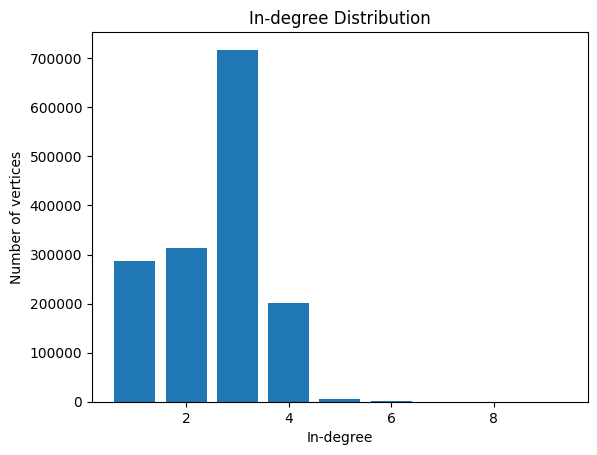

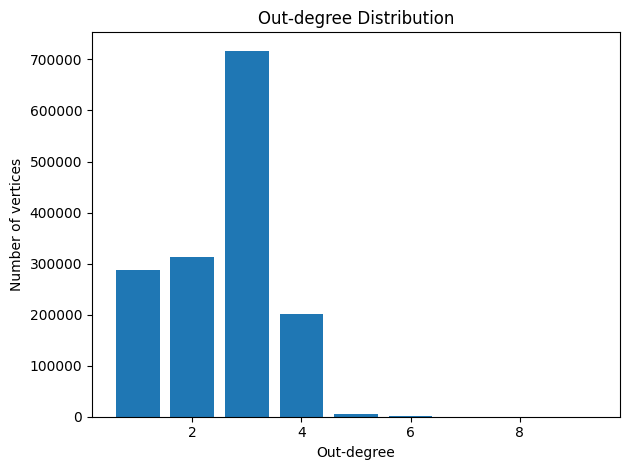

In [11]:
import matplotlib.pyplot as plt

in_degrees_x, in_counts_y = zip(*in_degree_hist_sorted)
out_degrees_x, out_counts_y = zip(*out_degree_hist_sorted)

plt.figure()
plt.bar(in_degrees_x, in_counts_y)
plt.xlabel("In-degree")
plt.ylabel("Number of vertices")
plt.title("In-degree Distribution")

plt.figure()
plt.bar(out_degrees_x, out_counts_y)
plt.xlabel("Out-degree")
plt.ylabel("Number of vertices")
plt.title("Out-degree Distribution")

plt.tight_layout()
plt.show()

Find the maximum in-degree and out-degree (and the vertex that has it):

In [12]:
# codecell_2c (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

######### BEGIN STUDENT CODE #########
max_in_vertex, max_in_deg = in_deg.max(key=lambda x: x[1])

max_out_vertex, max_out_deg = out_deg.max(key=lambda x: x[1])

######### END STUDENT CODE #########

print(f"Max in-degree  = {max_in_deg} (vertex = {max_in_vertex})")
print(f"Max out-degree = {max_out_deg} (vertex = {max_out_vertex})")

Max in-degree  = 9 (vertex = 1494340)
Max out-degree = 9 (vertex = 1494340)
